# Digit addition: one problem, four solutions

One problem, solved four ways. Each way builds on the one before, and each answers the same two
questions, so you can compare the numbers directly:

1. **Problem description**: what we know, and the two questions.
2. **Probability solution**: possible worlds, multiply and add, by hand.
3. **ProbLog solution**: write the rule as a logic program; ProbLog finds the worlds.
4. **DeepProbLog solution**: the chances come from a neural network, and the network learns.
5. **tididi solution**: what DeepProbLog does inside, built by hand with tididi circuits.

Background reading, in `docs/`: [learning guide](../docs/learning-guide.md) (the ideas, with exercises),
[how the digit-addition example works](../docs/digit-addition-explained.md) (pictures of the circuits).

Run it in this repo's environment (see the README), top to bottom. The DeepProbLog training cell takes
about 3 minutes; the other training cells take under a minute each.

## Setup

Shared by every section: the images, the training and test pairs, the network and the training loop.

In [1]:
import time
from fractions import Fraction as F
from itertools import product

import matplotlib.pyplot as plt
import torch
from sklearn.datasets import load_digits
from torch import nn

N = 10                       # digits 0..9
SUMS = range(2 * N - 1)      # possible sums 0..18
FEATURES = 64                # 8 x 8 pixels

# Real handwritten digits: 1,797 images of 8 x 8 pixels that ship inside scikit-learn.
digits = load_digits()
images = torch.tensor(digits.data, dtype=torch.float32) / 16   # [1797, 64], brightness 0..1
labels = torch.tensor(digits.target)                            # true digits: only for testing

# Split the images first, so no test pair reuses an image seen in training.
gen = torch.Generator().manual_seed(0)
order = torch.randperm(len(images), generator=gen)
train_pool, test_pool = order[:1300], order[1300:]


def make_pairs(n: int, pool: torch.Tensor) -> torch.Tensor:
    """n random pairs of image indices from the pool: [n, 2]."""
    return pool[torch.randint(0, len(pool), (n, 2), generator=gen)]


train_pairs = make_pairs(3000, train_pool)
test_pairs = make_pairs(1000, test_pool)
train_sums = labels[train_pairs].sum(dim=1)     # the ONLY thing training sees
test_sums = labels[test_pairs].sum(dim=1)
print(f"{len(images)} images: {len(train_pool)} for training, {len(test_pool)} for testing")
print(f"{len(train_pairs)} training pairs, {len(test_pairs)} test pairs")

1797 images: 1300 for training, 497 for testing
3000 training pairs, 1000 test pairs


In [2]:
def make_net() -> nn.Module:
    """The digit network: 64 pixels in, 10 digit chances out. Same starting weights every time."""
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(FEATURES, 64), nn.ReLU(), nn.Linear(64, N), nn.Softmax(dim=-1))


def digit_probs(net: nn.Module, pairs: torch.Tensor) -> torch.Tensor:
    """Run the network on both images of each pair: [B, 2] indices -> [B, 2, N] chances."""
    return net(images[pairs].reshape(-1, FEATURES)).reshape(-1, 2, N)


def accuracy(net: nn.Module) -> tuple[float, float]:
    """(digit accuracy, sum accuracy) on the test pairs.

    Digit accuracy checks each image's most likely digit against its true digit, which training
    never saw. Sum accuracy checks whether both digits are right enough to give the right sum.
    """
    with torch.no_grad():
        guess = digit_probs(net, test_pairs).argmax(dim=-1)
    digit_acc = (guess == labels[test_pairs]).float().mean().item()
    sum_acc = (guess.sum(dim=1) == test_sums).float().mean().item()
    return digit_acc, sum_acc


def train(net: nn.Module, p_sum, epochs: int = 5, batch: int = 32) -> None:
    """Train from sums only. p_sum turns digit chances [B, 2, N] into P(sum = s) [B, 19]."""
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    shuffle = torch.Generator().manual_seed(1)
    for epoch in range(1, epochs + 1):
        for i in torch.randperm(len(train_pairs), generator=shuffle).split(batch):
            p = p_sum(digit_probs(net, train_pairs[i]))                  # [B, 19]
            p_label = p.gather(1, train_sums[i, None]).squeeze(1)       # P(the true sum)
            loss = -p_label.clamp_min(1e-12).log().mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        digit_acc, sum_acc = accuracy(net)
        print(f"epoch {epoch}: test digit accuracy {digit_acc:.3f}, test sum accuracy {sum_acc:.3f}")


results = {}    # each section adds its numbers here; the last cell compares them

## 1. Problem description

We have pairs of handwritten digit images. For each pair we are told **only the sum** of the two
digits, never the digits themselves. Here are four training pairs exactly as training sees them:

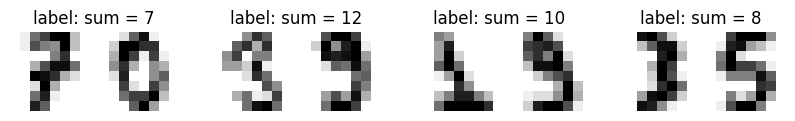

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.4))
for ax, (a, b), s in zip(axes, train_pairs[:4], train_sums[:4]):
    gap = torch.zeros(8, 1)
    pair = torch.cat([images[a].reshape(8, 8), gap, images[b].reshape(8, 8)], dim=1)
    ax.imshow(pair, cmap="gray_r")
    ax.set_title(f"label: sum = {s.item()}")
    ax.axis("off")
plt.show()

The network never sees the true digits: it gets each image as 64 numbers (pixel brightnesses) and
answers with 10 chances, one per digit. We ask two questions.

**Question 1 (inference).** A network has looked at a pair and made these guesses. How likely is
each sum? We use one running example: the same numbers as in the docs.

| Digit | 0 | 1 | each of 2–9 |
| --- | --- | --- | --- |
| Image 1 | 0.7 | 0.2 | 0.0125 |
| Image 2 | 0.1 | 0.8 | 0.0125 |

The sum 1 can only be 0 + 1 or 1 + 0, so the answer to check against is
P(sum = 1) = 0.7 × 0.8 + 0.2 × 0.1 = **0.58**.

**Question 2 (learning).** Train a network from the 3,000 training pairs and their sums alone. Then
test it on 1,000 pairs of images it has never seen, against their true digits.

In [4]:
GUESS1 = [F("0.7"), F("0.2")] + [F("0.0125")] * 8     # image 1: chance of each digit 0..9
GUESS2 = [F("0.1"), F("0.8")] + [F("0.0125")] * 8     # image 2
assert sum(GUESS1) == 1 and sum(GUESS2) == 1

## 2. Probability solution

A **possible world** is one answer for both images, such as "image 1 is 3 and image 2 is 5". There
are 10 × 10 = 100 worlds. Two school rules do everything:

- **Multiply**: the images are independent, so a world's chance is P(image 1 = a) × P(image 2 = b).
- **Add**: exactly one world is the real one, so worlds never overlap and their chances add.

```math
P(\text{sum} = s) = \sum_{a + b = s} P(\text{image 1} = a) \cdot P(\text{image 2} = b)
```

### Question 1

List every world, keep the ones whose digits add up to 1, and add their chances. Exact fractions,
no rounding.

In [5]:
def p_sum_by_worlds(p1, p2, s):
    """Add up the chance of every world (a, b) whose digits add up to s."""
    return sum(p1[a] * p2[b] for a, b in product(range(N), repeat=2) if a + b == s)


for a, b in product(range(N), repeat=2):
    if a + b == 1:
        print(f"world ({a}, {b}): {float(GUESS1[a])} × {float(GUESS2[b])} = {float(GUESS1[a] * GUESS2[b])}")
answer = p_sum_by_worlds(GUESS1, GUESS2, 1)
print(f"P(sum = 1) = {answer} = {float(answer)}")
results["Probability"] = {"P(sum = 1)": answer}

world (0, 1): 0.7 × 0.8 = 0.56
world (1, 0): 0.2 × 0.1 = 0.02
P(sum = 1) = 29/50 = 0.58


In [6]:
# Every sum at once. The 19 answers cover all 100 worlds between them, so they must add up to 1.
all_sums = [p_sum_by_worlds(GUESS1, GUESS2, s) for s in SUMS]
for s, p in enumerate(all_sums):
    print(f"P(sum = {s:2}) = {float(p):.6f}")
print("total:", sum(all_sums))

P(sum =  0) = 0.070000
P(sum =  1) = 0.580000
P(sum =  2) = 0.170000
P(sum =  3) = 0.022500
P(sum =  4) = 0.022656
P(sum =  5) = 0.022812
P(sum =  6) = 0.022969
P(sum =  7) = 0.023125
P(sum =  8) = 0.023281
P(sum =  9) = 0.023438
P(sum = 10) = 0.013594
P(sum = 11) = 0.001250
P(sum = 12) = 0.001094
P(sum = 13) = 0.000937
P(sum = 14) = 0.000781
P(sum = 15) = 0.000625
P(sum = 16) = 0.000469
P(sum = 17) = 0.000313
P(sum = 18) = 0.000156
total: 1


### Question 2

The same formula works on a whole batch of network outputs, as PyTorch tensors. Every step is a
multiply or an add, so PyTorch can work out how to nudge the network to make the true sum more likely.

In [7]:
# For each of the 100 worlds (a, b), in order, the sum it makes.
SUM_OF_WORLD = torch.tensor([a + b for a, b in product(range(N), repeat=2)])


def p_sum_formula(probs: torch.Tensor) -> torch.Tensor:
    """[B, 2, N] digit chances -> [B, 19] P(sum = s), straight from the formula."""
    worlds = (probs[:, 0, :, None] * probs[:, 1, None, :]).reshape(len(probs), N * N)   # multiply
    return torch.zeros(len(probs), len(SUMS)).index_add(1, SUM_OF_WORLD, worlds)          # add


example = torch.tensor([[[float(p) for p in GUESS1], [float(p) for p in GUESS2]]])
print("P(sum = 1) from the tensor formula:", round(p_sum_formula(example)[0, 1].item(), 6))

P(sum = 1) from the tensor formula: 0.58


In [8]:
net = make_net()
start = time.time()
train(net, p_sum_formula)
results["Probability"] |= dict(zip(["digit accuracy", "sum accuracy"], accuracy(net)),
                               seconds=time.time() - start)

epoch 1: test digit accuracy 0.435, test sum accuracy 0.231
epoch 2: test digit accuracy 0.839, test sum accuracy 0.713
epoch 3: test digit accuracy 0.915, test sum accuracy 0.839
epoch 4: test digit accuracy 0.948, test sum accuracy 0.902
epoch 5: test digit accuracy 0.944, test sum accuracy 0.893


**What this shows.** For a rule this simple we can write the formula by hand, and it works. But
every new rule needs a new formula: multi-digit numbers, a noisy label, "the first digit is
smaller"... Each one has to be worked out by hand, and a mistake gives wrong numbers without any
error. We would rather write the **rule** and have a system work out the arithmetic.

## 3. ProbLog solution

ProbLog lets us write the rule as a logic program. Each image's guesses become an **annotated
disjunction**: exactly one of its digits is true, with the given chances (`;` separates the options).

```prolog
0.7::digit(img1, 0); 0.2::digit(img1, 1); ...          % image 1 shows exactly one digit
addition(X, Y, S) :- digit(X, A), digit(Y, B), S is A + B.
query(addition(img1, img2, 1)).
```

The rule says: the sum is S if X shows A, Y shows B, and S is A + B. ProbLog finds the worlds itself.

### Question 1

In [9]:
from problog import get_evaluatable
from problog.formula import LogicFormula
from problog.program import PrologString


def choice(image: str, guess: list[F]) -> str:
    """An annotated disjunction: the image shows exactly one digit, with these chances."""
    return "; ".join(f"{float(p)}::digit({image}, {d})" for d, p in enumerate(guess)) + "."


rules = "\n".join([
    choice("img1", GUESS1),
    choice("img2", GUESS2),
    "addition(X, Y, S) :- digit(X, A), digit(Y, B), S is A + B.",
])
program = rules + "\nquery(addition(img1, img2, 1))."
print(program)

0.7::digit(img1, 0); 0.2::digit(img1, 1); 0.0125::digit(img1, 2); 0.0125::digit(img1, 3); 0.0125::digit(img1, 4); 0.0125::digit(img1, 5); 0.0125::digit(img1, 6); 0.0125::digit(img1, 7); 0.0125::digit(img1, 8); 0.0125::digit(img1, 9).
0.1::digit(img2, 0); 0.8::digit(img2, 1); 0.0125::digit(img2, 2); 0.0125::digit(img2, 3); 0.0125::digit(img2, 4); 0.0125::digit(img2, 5); 0.0125::digit(img2, 6); 0.0125::digit(img2, 7); 0.0125::digit(img2, 8); 0.0125::digit(img2, 9).
addition(X, Y, S) :- digit(X, A), digit(Y, B), S is A + B.
query(addition(img1, img2, 1)).


In [10]:
result = get_evaluatable().create_from(PrologString(program)).evaluate()
for query, p in result.items():
    print(f"{query}: {p:.6f}")
results["ProbLog"] = {"P(sum = 1)": next(iter(result.values()))}

# A variable S asks for every sum at once. Compare with the exact answers from section 2.
every = get_evaluatable().create_from(PrologString(rules + "\nquery(addition(img1, img2, S)).")).evaluate()
worst = max(abs(p - float(all_sums[int(str(q.args[2]))])) for q, p in every.items())
print(f"all {len(every)} sums: largest difference from section 2 = {worst:.1e}")

addition(img1,img2,1): 0.580000
all 19 sums: largest difference from section 2 = 4.2e-17


### What ProbLog does inside

ProbLog first **grounds** the program: it fills in the variables with every value that could make the
query true, and keeps only the logic that matters. The result is a small AND/OR formula over the
digit choices. Read it bottom up: each AND is one way to make the sum, and the OR joins the ways.
This is the same shape as the circuit for sum = 1 in the docs, and it is exactly what an automatic
ProbLog-to-tididi compiler would start from.

In [11]:
ground = LogicFormula.create_from(PrologString(program), label_all=True)
names = {}
for key, node, kind in ground:
    if kind == "atom" and not node.is_extra:
        names[key] = str(node.name.args[2])          # choice(_, _, digit(img1, 0)) -> digit(img1, 0)
        print(f"{key:3}: {names[key]}  with chance {node.probability}")
    elif kind == "conj":
        names[key] = " AND ".join(names[c] for c in node.children)
        print(f"{key:3}: AND  {names[key]}")
    elif kind == "disj":
        print(f"{key:3}: OR   of nodes {list(node.children)}  <- {node.name}")

  1: digit(img1,0)  with chance 0.7
  2: digit(img1,1)  with chance 0.2
  4: digit(img1,2)  with chance 0.0125
  5: digit(img1,3)  with chance 0.0125
  6: digit(img1,4)  with chance 0.0125
  7: digit(img1,5)  with chance 0.0125
  8: digit(img1,6)  with chance 0.0125
  9: digit(img1,7)  with chance 0.0125
 10: digit(img1,8)  with chance 0.0125
 11: digit(img1,9)  with chance 0.0125
 12: digit(img2,0)  with chance 0.1
 13: digit(img2,1)  with chance 0.8
 15: digit(img2,2)  with chance 0.0125
 16: digit(img2,3)  with chance 0.0125
 17: digit(img2,4)  with chance 0.0125
 18: digit(img2,5)  with chance 0.0125
 19: digit(img2,6)  with chance 0.0125
 20: digit(img2,7)  with chance 0.0125
 21: digit(img2,8)  with chance 0.0125
 22: digit(img2,9)  with chance 0.0125
 23: AND  digit(img1,0) AND digit(img2,1)
 24: AND  digit(img1,1) AND digit(img2,0)
 25: OR   of nodes [23, 24]  <- addition(img1,img2,1)


**What ProbLog can't do.** The 0.7 and 0.2 are typed into the program. ProbLog has no way to get
them from pixels, and nothing to learn: Question 2 is out of reach.

## 4. DeepProbLog solution

DeepProbLog changes one line. The digit chances come from a neural network instead of being typed in:

```prolog
nn(digit_net, [X], D, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]) :: digit(X, D).
addition(X, Y, S) :- digit(X, A), digit(Y, B), S is A + B.
```

The rule is unchanged. To answer a query, DeepProbLog grounds it as ProbLog does, compiles it into a
circuit (an SDD, through the PySDD library), and evaluates the circuit with the network's outputs.
Because the circuit only multiplies and adds, PyTorch can train the network through it.

In [12]:
from problog.logic import Constant, Term

from deepproblog.dataset import DataLoader, Dataset
from deepproblog.engines import ExactEngine
from deepproblog.model import Model
from deepproblog.network import Network
from deepproblog.query import Query
from deepproblog.train import train_model

DPL_PROGRAM = """
nn(digit_net, [X], D, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]) :: digit(X, D).
addition(X, Y, S) :- digit(X, A), digit(Y, B), S is A + B.
"""


def addition_query(source: str, a: int, b: int, s: int) -> Query:
    """The query addition(image a, image b, s), with images looked up in a tensor source."""
    image = lambda i: Term("tensor", Term(source, Constant(i)))
    return Query(Term("addition", image(a), image(b), Constant(s)))

### Question 1

To get the running example's numbers out of DeepProbLog, we give it a stand-in "network" that ignores
its input and returns the guesses for image 1 or image 2.

In [13]:
class FixedGuesses(nn.Module):
    """A stand-in network: input 0 gives image 1's guesses, input 1 gives image 2's."""

    def __init__(self):
        super().__init__()
        self.rows = torch.tensor([[float(p) for p in GUESS1], [float(p) for p in GUESS2]])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.rows[x.long().view(-1)]


class ExampleIds:
    """Tensor source: example(i) is just the number i."""

    def __getitem__(self, item):
        return torch.tensor([int(item[0])])


model = Model(DPL_PROGRAM, [Network(FixedGuesses(), "digit_net", batching=True)], load=False)
model.set_engine(ExactEngine(model))
model.add_tensor_source("example", ExampleIds())
answer = model.solve([addition_query("example", 0, 1, 1)])[0]
for query, p in answer.result.items():
    print(f"{query}: {p.item():.6f}")
results["DeepProbLog"] = {"P(sum = 1)": next(iter(answer.result.values())).item()}

addition(tensor(example(0)),tensor(example(1)),1): 0.580000


### Question 2

Now the real network. DeepProbLog needs two adapters: a **tensor source** that hands it an image by
number, and a **dataset** that turns training pair i into the query "these two images add up to their
label". Same network, same starting weights, same 3,000 pairs as section 2. Takes about 3 minutes.

In [14]:
class DigitImages:
    """Tensor source: digits(i) is image i's 64 pixels."""

    def __getitem__(self, item):
        return images[int(item[0])]


class TrainingPairs(Dataset):
    """Training pair i as a query: addition(image a, image b, their sum)."""

    def __len__(self):
        return len(train_pairs)

    def to_query(self, i: int) -> Query:
        a, b = train_pairs[i].tolist()
        return addition_query("digits", a, b, train_sums[i].item())


net = make_net()
network = Network(net, "digit_net", batching=True)
network.optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
model = Model(DPL_PROGRAM, [network], load=False)
model.set_engine(ExactEngine(model), cache=True)   # cache: compile each query shape once
model.add_tensor_source("digits", DigitImages())

start = time.time()
for epoch in range(1, 6):
    train_model(model, DataLoader(TrainingPairs(), 32, shuffle=True), 1, log_iter=1000, verbose=0)
    digit_acc, sum_acc = accuracy(net)
    print(f"epoch {epoch}: test digit accuracy {digit_acc:.3f}, test sum accuracy {sum_acc:.3f}")
results["DeepProbLog"] |= dict(zip(["digit accuracy", "sum accuracy"], accuracy(net)),
                               seconds=time.time() - start)

Caching ACs


Training  for 1 epoch(s)


epoch 1: test digit accuracy 0.470, test sum accuracy 0.243


Training  for 1 epoch(s)


epoch 2: test digit accuracy 0.817, test sum accuracy 0.680
Training  for 1 epoch(s)


epoch 3: test digit accuracy 0.920, test sum accuracy 0.849
Training  for 1 epoch(s)


epoch 4: test digit accuracy 0.933, test sum accuracy 0.872
Training  for 1 epoch(s)


epoch 5: test digit accuracy 0.952, test sum accuracy 0.908


**What this shows.** We wrote two lines of logic and DeepProbLog did the rest: the worlds, the
circuit and the training. The cost is speed: it is much slower than the hand-written formula, and the
circuits come from SDDs. The project's goal is to use **tididi** as that circuit engine. The next
section does by hand what DeepProbLog does inside, with tididi.

## 5. tididi solution

tididi builds circuits over yes/no variables, so the digit choices become switches:

- **Switches.** Each image gets ten: "image 1 is a 0", "image 1 is a 1", ... That makes 20 variables:
  image 1 uses 1–10, image 2 uses 11–20.
- **Exactly one switch per image is on.** This is the annotated disjunction, as logic.
- **One circuit per sum.** For sum s: OR over the ways a + b = s of (image 1 is a AND image 2 is b),
  AND the exactly-one rules. 19 circuits, built once, before training.
- **Weights.** A switch weighs its chance when on, and 1 when off.

The circuit for sum = 1, as tididi builds it (labels added by hand; see the
[explainer](../docs/digit-addition-explained.md) for how to read it):

![The real tididi circuit for sum = 1](../docs/images/circuit-sum-1.png)

In [15]:
import tididi


def var(image: int, digit: int) -> int:
    """Switch variable for "image shows digit": image 0 uses 1..10, image 1 uses 11..20."""
    return 1 + image * N + digit


def exactly_one(vt: tididi.Vtree, variables: list[int]) -> tididi.Circuit:
    """Circuit: at least one of the variables is on, and no two are on together."""
    f = tididi.clause(vt, variables)                        # circuit: "at least one" (an OR)
    for i, a in enumerate(variables):
        for b in variables[i + 1:]:
            f = f & tididi.clause(vt, [-a, -b])             # AND "not both a and b"
    return f


image1 = [var(0, d) for d in range(N)]
image2 = [var(1, d) for d in range(N)]
# The vtree is the layout: image 1's switches on one side, image 2's on the other.
vt = tididi.Vtree.join(tididi.Vtree.balanced_over(image1), tididi.Vtree.balanced_over(image2))
domain = exactly_one(vt, image1) & exactly_one(vt, image2)  # circuit: each image shows one digit

circuits = []
for s in SUMS:
    # One cube per way of making s: circuit "image 1 is a AND image 2 is s - a".
    ways = [tididi.cube(vt, [var(0, a), var(1, s - a)]) for a in range(N) if 0 <= s - a < N]
    # or_many: "any of these ways". & consumes its inputs, so AND with a copy of the domain.
    circuits.append(tididi.or_many(ways) & domain.copy())

print("circuit sizes (pairs), sums 0..18:", [c.pair_count() for c in circuits])

circuit sizes (pairs), sums 0..18: [53, 60, 67, 72, 77, 82, 85, 88, 91, 94, 91, 88, 85, 82, 77, 72, 65, 56, 47]


### Question 1

`weighted_count` takes each switch's (weight when off, weight when on) and computes the circuit's
answer exactly, as a fraction.

In [16]:
weights = {var(0, d): (F(1), GUESS1[d]) for d in range(N)}   # switch weights: off 1, on p
weights |= {var(1, d): (F(1), GUESS2[d]) for d in range(N)}

answer = circuits[1].weighted_count(weights)
print(f"P(sum = 1) = {answer} = {float(answer)}")
results["tididi"] = {"P(sum = 1)": answer}

# All 19 circuits against section 2's possible-worlds answers, exactly.
assert all(c.weighted_count(weights) == p for c, p in zip(circuits, all_sums))
print("all 19 circuits match the possible-worlds answers exactly")

P(sum = 1) = 29/50 = 0.58
all 19 circuits match the possible-worlds answers exactly


### Question 2

For training, the circuit is evaluated with PyTorch tensors instead of fractions. tididi walks the
circuit and asks an **algebra** four questions: what an impossible branch is worth (`zero`), what a
switch is worth (`leaf`), how to combine at an OR (`add`) and at an AND (`mul`). Our algebra answers
with the network's chances, for a whole batch at once.

In [17]:
class TorchProbability:
    """tididi algebra over batched tensors: switch on -> p, off -> 1, free -> 1 + p."""

    def __init__(self, probs: torch.Tensor):     # probs: [B, 2, N]
        self.probs = probs
        self.ones = torch.ones(len(probs))

    def zero(self):
        return torch.zeros_like(self.ones)

    def leaf(self, variable: int, sign: bool | None):
        image, digit = divmod(variable - 1, N)
        p = self.probs[:, image, digit]
        if sign is None:                          # a free switch: off weight + on weight
            return self.ones + p
        return p if sign else self.ones

    def add(self, a, b):
        return a + b

    def mul(self, a, b):
        return a * b


def p_sum_tididi(probs: torch.Tensor) -> torch.Tensor:
    """[B, 2, N] digit chances -> [B, 19] P(sum = s), by evaluating the 19 circuits."""
    algebra = TorchProbability(probs)
    return torch.stack([c.evaluate(algebra) for c in circuits], dim=1)


random_probs = torch.rand(5, 2, N).softmax(dim=-1)
gap = (p_sum_tididi(random_probs) - p_sum_formula(random_probs)).abs().max().item()
print(f"tididi vs the section 2 formula on random chances: largest difference {gap:.1e}")

tididi vs the section 2 formula on random chances: largest difference 0.0e+00


In [18]:
net = make_net()
start = time.time()
train(net, p_sum_tididi)
results["tididi"] |= dict(zip(["digit accuracy", "sum accuracy"], accuracy(net)),
                          seconds=time.time() - start)

epoch 1: test digit accuracy 0.435, test sum accuracy 0.231


epoch 2: test digit accuracy 0.839, test sum accuracy 0.713


epoch 3: test digit accuracy 0.915, test sum accuracy 0.839


epoch 4: test digit accuracy 0.948, test sum accuracy 0.902


epoch 5: test digit accuracy 0.944, test sum accuracy 0.893


## Comparison

In [19]:
print(f"{'solution':12} {'P(sum = 1)':>11} {'digit acc':>10} {'sum acc':>8} {'train time':>11}")
for name, r in results.items():
    acc = (f"{r['digit accuracy']:10.3f} {r['sum accuracy']:8.3f} {r['seconds']:10.0f}s"
           if "seconds" in r else f"{'—':>10} {'—':>8} {'—':>11}")
    print(f"{name:12} {float(r['P(sum = 1)']):11.6f} {acc}")

solution      P(sum = 1)  digit acc  sum acc  train time
Probability     0.580000      0.944    0.893          1s
ProbLog         0.580000          —        —           —
DeepProbLog     0.580000      0.952    0.908        182s
tididi          0.580000      0.944    0.893          8s


**What to take away.**

- **Question 1:** all four give 0.58. They are the same mathematics: worlds, multiply, add. The
  probability and tididi solutions are exact fractions; ProbLog and DeepProbLog use floating point.
- **Question 2:** the three learners all read most test digits correctly, without ever seeing a digit
  label. The probability and tididi solutions compute the same numbers in the same order, so they
  train the network identically. DeepProbLog shuffles its batches differently, so its numbers differ
  slightly, and it is the slowest.
- **What's next:** section 5 built tididi's circuits by hand from the rule. Section 3 showed the ground
  formula ProbLog produces. Turning that formula into tididi circuits automatically would let tididi
  run any DeepProbLog program, not just this one.